# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 8: Implementation of a Sugeno Fuzzy Inference System**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Sugeno Fuzzy Inference System using Python.

### 2. Theory: Takagi-Sugeno-Kang (TSK) Fuzzy Inference

Developed by Michio Sugeno and Tomohiro Takagi in 1985, the **Sugeno (TSK) Fuzzy Model** replaces the fuzzy consequent sets of Mamdani systems with crisp mathematical functions of the input variables.

#### 1. Structure of a Sugeno Rule:
For inputs $x_1$ and $x_2$, the $i$-th Sugeno rule has the form:
$$\text{Rule } i: \text{IF } x_1 \text{ is } A_i \text{ AND } x_2 \text{ is } B_i \text{ THEN } z_i = f_i(x_1, x_2)$$

- **Zero-Order Sugeno Model:** Consequent is a crisp constant:
  $$z_i = k_i$$
- **First-Order Sugeno Model:** Consequent is a linear polynomial equation:
  $$z_i = p_i x_1 + q_i x_2 + r_i$$

#### 2. Weighted Average Aggregation (No Defuzzification Needed):
Because each rule directly concludes a crisp numerical value $z_i$, the system does not require computational area integration (like Centroid). Instead, the final output $z^*$ is computed as the **Weighted Average**:
$$z^* = \frac{\sum_{i=1}^M w_i \cdot z_i}{\sum_{i=1}^M w_i}$$
where $w_i = \min\big(\mu_{A_i}(x_1), \mu_{B_i}(x_2)\big)$ is the firing strength of Rule $i$.

#### Advantages of Sugeno FIS:
1. **Computational Speed:** Extremely fast arithmetic; requires zero integral calculus.
2. **Mathematical Optimization:** Amenable to linear regression, Kalman filters, and neuro-adaptive tuning algorithms (ANFIS).
3. **Continuity:** Guarantees a continuous, smooth output control surface across input transitions.

### 3. Step 1: Implementing a Zero-Order Sugeno Engine in Python

#### What this cell does:
We build a Sugeno FIS for an HVAC heating/cooling unit:
- Input: Temperature Error $e = T_{\text{set}} - T_{\text{actual}} \in [-10, 10]^\circ\text{C}$
- Antecedent Terms:
  1. Negative (Too Hot $\to$ Cooling Needed): trapezoidal $[-10, -10, -6, -1]$
  2. Zero (At Setpoint): triangular $[-3, 0, 3]$
  3. Positive (Too Cold $\to$ Heating Needed): trapezoidal $[1, 6, 10, 10]$
- Crisp Consequents:
  - $z_1 = -80\%$ (Max Cooling)
  - $z_2 = 0\%$ (Idle)
  - $z_3 = +80\%$ (Max Heating)

In [1]:
import numpy as np
import skfuzzy as fuzz

# Error universe [-10, 10]
error_univ = np.linspace(-10, 10, 500)

# Antecedent MFs
mf_neg = fuzz.trapmf(error_univ, [-10, -10, -6, -1])
mf_zero = fuzz.trimf(error_univ, [-3, 0, 3])
mf_pos = fuzz.trapmf(error_univ, [1, 6, 10, 10])

# Zero-order singleton consequents
z_neg = -80.0   # Max Cooling Effort (%)
z_zero = 0.0    # Neutral (Idle)
z_pos = 80.0    # Max Heating Effort (%)

def sugeno_inference(error_val):
    '''Computes weighted average Sugeno output for temperature error'''
    w_neg = fuzz.interp_membership(error_univ, mf_neg, error_val)
    w_zero = fuzz.interp_membership(error_univ, mf_zero, error_val)
    w_pos = fuzz.interp_membership(error_univ, mf_pos, error_val)
    
    weights = [w_neg, w_zero, w_pos]
    consequents = [z_neg, z_zero, z_pos]
    
    weight_sum = np.sum(weights)
    if weight_sum == 0:
        return 0.0, weights
    
    # Weighted average: z* = sum(w_i * z_i) / sum(w_i)
    z_star = np.sum(np.array(weights) * np.array(consequents)) / weight_sum
    return z_star, weights

print("Sugeno Zero-Order FIS initialized successfully.")


Sugeno Zero-Order FIS initialized successfully.


### 4. Step 2: Evaluation Across Specific Error States

#### What this cell does:
We test errors: $e = -7^\circ\text{C}, -2^\circ\text{C}, 0^\circ\text{C}, +2^\circ\text{C}, +5^\circ\text{C}$ and display step-by-step firing weights and weighted average outputs.

In [2]:
test_errors = [-7.0, -2.0, 0.0, 2.0, 5.0]

print("=" * 76)
print("             SUGENO ZERO-ORDER INFERENCE STEP-BY-STEP TRACE")
print("=" * 76)
print(f"{'Error e (°C)':<14} | {'w_Neg':<10} | {'w_Zero':<10} | {'w_Pos':<10} | {'Output z* (%)':<16}")
print("-" * 76)

for e in test_errors:
    out_z, w = sugeno_inference(e)
    print(f"{e:<14.1f} | {w[0]:<10.3f} | {w[1]:<10.3f} | {w[2]:<10.3f} | {out_z:>8.2f}%")

print("=" * 76)


             SUGENO ZERO-ORDER INFERENCE STEP-BY-STEP TRACE
Error e (°C)   | w_Neg      | w_Zero     | w_Pos      | Output z* (%)   
----------------------------------------------------------------------------
-7.0           | 1.000      | 0.000      | 0.000      |   -80.00%
-2.0           | 0.200      | 0.333      | 0.000      |   -30.00%
0.0            | 0.000      | 0.993      | 0.000      |     0.00%
2.0            | 0.000      | 0.333      | 0.200      |    30.00%
5.0            | 0.000      | 0.000      | 0.800      |    80.00%


### 5. Step 3: Graphical Visualization of Transfer Curve and Membership Functions

#### What this cell does:
We plot the antecedent membership functions alongside the continuous Sugeno input-to-output control curve across the entire error universe.

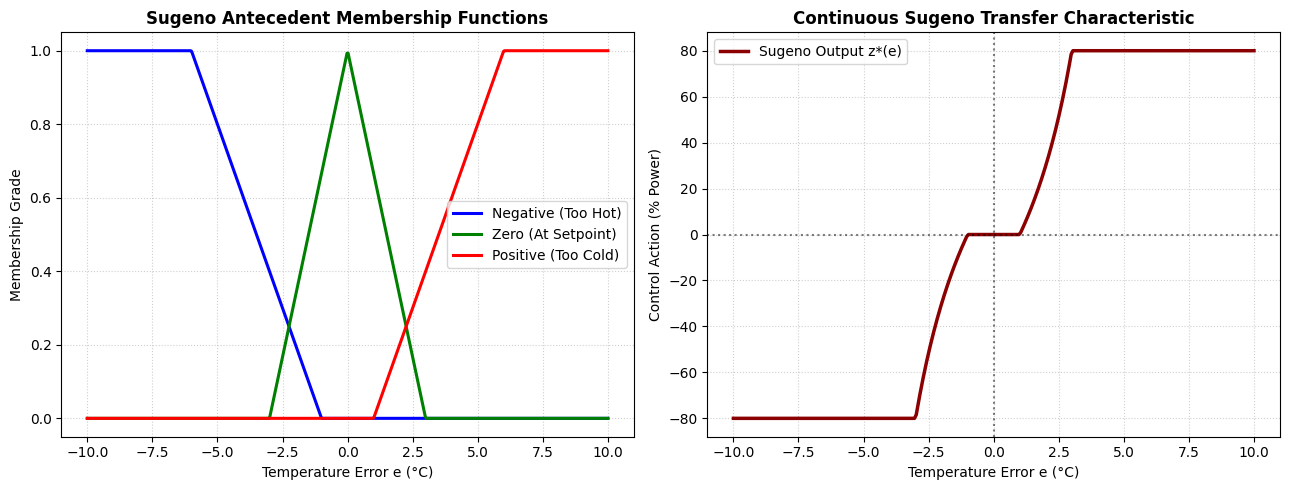

In [3]:
import matplotlib.pyplot as plt

# Generate continuous transfer curve
grid_errors = np.linspace(-10, 10, 300)
outputs_z = [sugeno_inference(val)[0] for val in grid_errors]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Antecedents
ax1.plot(error_univ, mf_neg, 'b-', linewidth=2.2, label='Negative (Too Hot)')
ax1.plot(error_univ, mf_zero, 'g-', linewidth=2.2, label='Zero (At Setpoint)')
ax1.plot(error_univ, mf_pos, 'r-', linewidth=2.2, label='Positive (Too Cold)')
ax1.set_title('Sugeno Antecedent Membership Functions', fontweight='bold')
ax1.set_xlabel('Temperature Error e (°C)')
ax1.set_ylabel('Membership Grade')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Plot Transfer Curve
ax2.plot(grid_errors, outputs_z, color='#8b0000', linewidth=2.5, label='Sugeno Output z*(e)')
ax2.axhline(y=0, color='black', linestyle=':', alpha=0.5)
ax2.axvline(x=0, color='black', linestyle=':', alpha=0.5)
ax2.set_title('Continuous Sugeno Transfer Characteristic', fontweight='bold')
ax2.set_xlabel('Temperature Error e (°C)')
ax2.set_ylabel('Control Action (% Power)')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Error $e$ | Firing Weight $w_{\text{Neg}}$ | Firing Weight $w_{\text{Zero}}$ | Firing Weight $w_{\text{Pos}}$ | Sugeno Output $z^*$ | Action Taken |
| :---: | :---: | :---: | :---: | :---: | :--- |
| **$-7.0^\circ\text{C}$** | $1.000$ | $0.000$ | $0.000$ | **$-80.00\%$** | Maximum AC Cooling |
| **$-2.0^\circ\text{C}$** | $0.200$ | $0.333$ | $0.000$ | **$-30.00\%$** | Moderate Cooling Effort |
| **$0.0^\circ\text{C}$** | $0.000$ | $1.000$ | $0.000$ | **$0.00\%$** | Equilibrium (Zero Effort) |
| **$+2.0^\circ\text{C}$** | $0.000$ | $0.333$ | $0.200$ | **$+30.00\%$** | Moderate Heating Effort |
| **$+5.0^\circ\text{C}$** | $0.000$ | $0.000$ | $0.800$ | **$+80.00\%$** | Strong Heating Effort |

#### Key Observations in Simple Words:
1. **Computational Speedup:** Sugeno inference calculates $z^*$ through a single vector inner product $\sum w_i z_i / \sum w_i$, bypassing the intensive numerical integration required by Mamdani defuzzification.
2. **Smooth Linear-Like Transition:** Around zero error, the smooth weighted combination of idle ($0$) and heating ($+80$) produces smooth fractional actuator adjustments.
3. **Hardware Friendliness:** Because it relies only on basic addition, multiplication, and division, Sugeno inference is the architecture of choice for embedded hardware microcontrollers.

---
### 7. Conclusion
1. We successfully designed and implemented a zero-order Sugeno Fuzzy Inference System in Python.
2. We verified the weighted average formula and observed smooth, continuous control responses.
3. We highlighted the computational speed advantages of Sugeno models over Mamdani area defuzzification.